<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_9/dataset_pbl/kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install mglearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.4/581.4 kB 8.0 MB/s  0:00:00


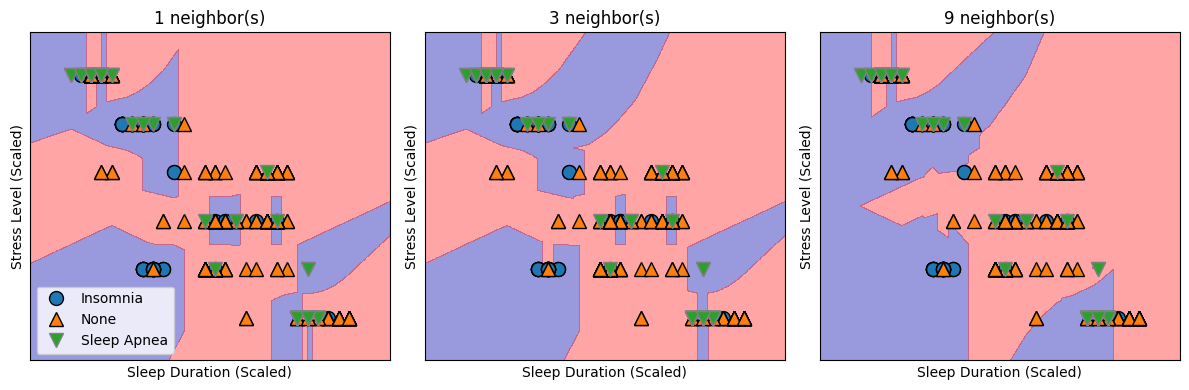

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
import pandas as pd
import mglearn

# Baca dataset Sleep Health
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')

# Ambil 2 fitur utama untuk visualisasi 2D
X_2d = df[['Sleep Duration', 'Stress Level']].values
le = LabelEncoder()
y_2d = le.fit_transform(df['Sleep Disorder'])

# Standarisasi fitur
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for n_neighbors, ax in zip([1, 3, 9], axes):
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X_2d_scaled, y_2d)
    mglearn.plots.plot_2d_separator(clf, X_2d_scaled, fill=True, eps=0.5, ax=ax, alpha=.4)
    mglearn.discrete_scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], y_2d, ax=ax)
    ax.set_title(f"{n_neighbors} neighbor(s)")
    ax.set_xlabel("Sleep Duration (Scaled)")
    ax.set_ylabel("Stress Level (Scaled)")

axes[0].legend(le.classes_, loc=3)
plt.tight_layout()
plt.show()

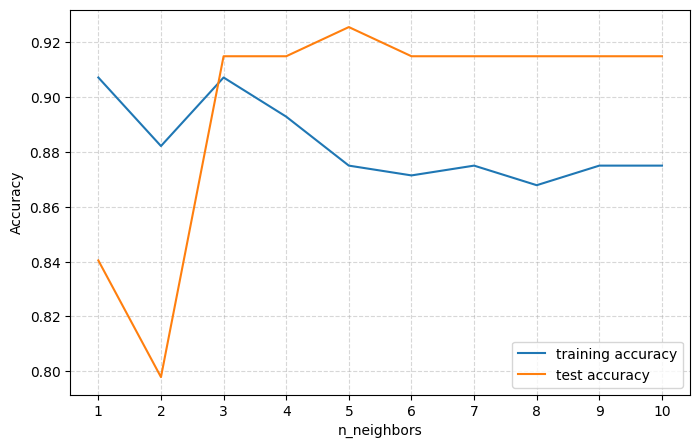

In [4]:
# Preprocessing seluruh fitur dataset
df_clean = df.drop(columns=['Person ID'], errors='ignore')
df_clean['Sleep Disorder'] = df_clean['Sleep Disorder'].fillna('None')

# Pisahkan kolom Blood Pressure menjadi Systolic dan Diastolic
if 'Blood Pressure' in df_clean.columns:
    bp_split = df_clean['Blood Pressure'].str.split('/', expand=True)
    df_clean['Systolic_BP'] = pd.to_numeric(bp_split[0])
    df_clean['Diastolic_BP'] = pd.to_numeric(bp_split[1])
    df_clean = df_clean.drop(columns=['Blood Pressure'])

# Pisahkan target dan fitur
y = le.fit_transform(df_clean['Sleep Disorder'])
X = pd.get_dummies(df_clean.drop(columns=['Sleep Disorder']), drop_first=True)

# Pembagian data latih dan data uji (stratify menjaga proporsi kelas tetap seimbang)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=66
)

# Standarisasi fitur (wajib untuk kNN agar skala fitur seragam)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

training_accuracy = []
test_accuracy = []
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)
    clf.fit(X_train_scaled, y_train)
    training_accuracy.append(clf.score(X_train_scaled, y_train))
    test_accuracy.append(clf.score(X_test_scaled, y_test))

plt.figure(figsize=(8, 5))
plt.plot(neighbors_settings, training_accuracy, label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, label="test accuracy")
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.xticks(neighbors_settings)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()